#  Notebook 4: Swin-Tiny Transformer — Binary Classifier

## Why a Transformer for Skin Lesions?
CNNs (EfficientNet, DenseNet) extract features **locally** —
they examine small patches of pixels at a time.

**Vision Transformers use Self-Attention** — the model looks at
the **entire image globally**, understanding *how the irregular
border on the left* relates to *the discolored center on the right*.
This global view is critical for melanoma detection.

## Why Swin-TINY specifically?
- `Swin-Base` and `Swin-Large` are too heavy for a 12-hour Kaggle session
  with ISIC 2019's 25K images
- `Swin-Tiny` (28M parameters) gives the **global attention benefit**
  while training in ~3–4 hours on a T4/P100
- Pre-trained on **ImageNet-21K** (not just ImageNet-1K), giving it
  much richer visual priors

## Special Considerations for Transformers
- Use **smaller batch size** (16 instead of 32) — Transformers use more VRAM
- Enable **Gradient Accumulation** (accumulate over 2 steps = effective batch of 32)
- Slightly **lower learning rate** (5e-5) — Transformers are sensitive to high LRs

In [1]:
# ── CODE CELL 1: Install & Import ─────────────────────────────────────
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torchvision.transforms as T
import timm

from sklearn.metrics import (roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️  Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU : {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

🖥️  Device: cuda
   GPU : Tesla T4
   VRAM: 15.6 GB


## Configuration
⚠️ **Note:** Batch size is 16 (not 32) to avoid VRAM overflow.
Gradient Accumulation (accum_steps=2) gives us an effective batch of 32.
LR is lower (5e-5) because Vision Transformers are sensitive to high LRs.

In [2]:
# ── CODE CELL 2: Config ────────────────────────────────────────────────
INPUT_CSV_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'
OUTPUT_DIR    = '/kaggle/working/'

IMG_SIZE      = 224
BATCH_SIZE    = 16    # Half of CNNs due to Transformer VRAM usage
ACCUM_STEPS   = 2     # Gradient accumulation → effective batch = 32
NUM_EPOCHS    = 30
LR            = 5e-5  # Lower LR for Transformers
WEIGHT_DECAY  = 1e-2
PATIENCE      = 7
WARMUP_EPOCHS = 2      # Gradual unfreezing: backbone frozen for first N epochs
MODEL_NAME    = 'swin_tiny_patch4_window7_224'
SAVE_PATH     = os.path.join(OUTPUT_DIR, 'swin_tiny_best.pth')

print("=" * 60)
print(f"  Model          : {MODEL_NAME}")
print(f"  Image Size     : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size     : {BATCH_SIZE} (effective {BATCH_SIZE*ACCUM_STEPS} with accumulation)")
print(f"  LR             : {LR}")
print(f"  Max Epochs     : {NUM_EPOCHS}")
print(f"  Warmup Epochs  : {WARMUP_EPOCHS} (backbone frozen during warmup)")
print(f"  Early Stopping : patience={PATIENCE}")
print("=" * 60)
# ── Multi-Modal Metadata Config (Phase 2) ────────────────────────────────
META_DIM    = 11   # age_norm(1) + sex_encoded(1) + site_one_hot(9)
META_HIDDEN = 32   # Hidden units in Tabular MLP branch
USE_CUTMIX  = True
CUTMIX_PROB = 0.3


  Model          : swin_tiny_patch4_window7_224
  Image Size     : 224x224
  Batch Size     : 16 (effective 32 with accumulation)
  LR             : 5e-05
  Max Epochs     : 30
  Warmup Epochs  : 2 (backbone frozen during warmup)
  Early Stopping : patience=7


## Dataset
Identical to Notebooks 2 & 3. Swin-Tiny expects the same
224x224 images normalized with ImageNet mean and std.

In [3]:
# ── CODE CELL: Multi-Modal Dataset ────────────────────────────────────────────
METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown'
]

class ISICDataset(Dataset):
    """Multi-Modal: returns (image_tensor, metadata_tensor, label_tensor)"""
    def __init__(self, df, transform, is_train=True):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
        self.is_train  = is_train
        self.meta_cols = [c for c in METADATA_COLS if c in df.columns]
        if not self.meta_cols:
            print("  WARNING: No metadata columns found! Using zero vectors.")
        else:
            print(f"  Dataset: {len(df)} rows | {len(self.meta_cols)} metadata features")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        if self.meta_cols:
            meta = torch.tensor(row[self.meta_cols].values.astype('float32'), dtype=torch.float32)
        else:
            meta = torch.zeros(META_DIM, dtype=torch.float32)
        return image, meta, label


In [4]:
# ── CODE CELL: Augmentation (CLAHE + CoarseDropout) ───────────────────────────
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_albu = A.Compose([
    A.Resize(int(IMG_SIZE * 1.12), int(IMG_SIZE * 1.12)),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.2, rotate_limit=15, p=0.5),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.4),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
val_albu = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class AlbuTransform:
    def __init__(self, pipeline):
        self.pipeline = pipeline
    def __call__(self, pil_img):
        img_np = np.array(pil_img)
        return self.pipeline(image=img_np)['image']

train_transforms = AlbuTransform(train_albu)
val_transforms   = AlbuTransform(val_albu)
print("Transforms: CLAHE + CoarseDropout added (Phase 2)")


Transforms: CLAHE + CoarseDropout added (Phase 2)


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_23/2186101792.py:18: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),


In [5]:
# ── CODE CELL 4: Create DataLoaders (UPDATED) ─────────────────────────
train_df = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_train.csv'))
val_df   = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_val.csv'))
test_df  = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_test.csv'))

# 🔧 THE FIX: Dynamically update the file paths in memory
OLD_PATH = '/kaggle/working/preprocessed/'
NEW_PATH = f'{INPUT_CSV_DIR}/preprocessed/'

train_df['image_path'] = train_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
val_df['image_path']   = val_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
test_df['image_path']  = test_df['image_path'].str.replace(OLD_PATH, NEW_PATH)

train_loader = DataLoader(ISICDataset(train_df, train_transforms, True),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(ISICDataset(val_df,   val_transforms,   False),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)
test_loader  = DataLoader(ISICDataset(test_df,  val_transforms,   False),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

print(f"📦 DataLoaders ready:")
print(f"   Train: {len(train_loader)} batches | Val: {len(val_loader)} | Test: {len(test_loader)}")

  Dataset: 20264 rows | 11 metadata features
  Dataset: 2533 rows | 11 metadata features
  Dataset: 2534 rows | 11 metadata features
📦 DataLoaders ready:
   Train: 1267 batches | Val: 159 | Test: 159


## Swin-Tiny Model Architecture
`swin_tiny_patch4_window7_224` from timm:
- Patch size: 4 (divides 224x224 into 56x56 patches)
- Window size: 7x7 local self-attention windows
- Shifted window attention for cross-window interaction
- 28M parameters — lightweight Transformer ideal for Kaggle

In [6]:
# ── CODE CELL 5: Focal Loss ────────────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, label_smoothing=0.02):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        # Apply gentle label smoothing (0.02) to prevent overconfidence
        if self.label_smoothing > 0:
            targets = targets * (1 - self.label_smoothing) + 0.5 * self.label_smoothing
        bce   = nn.functional.binary_cross_entropy_with_logits(
                    logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t   = probs * targets + (1 - probs) * (1 - targets)
        alpha = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = alpha * (1 - p_t) ** self.gamma * bce
        return focal.mean()


In [7]:
# ── CODE CELL 6: Build Swin-Tiny Model (UPDATED) ──────────────────────

class SwinPooler(nn.Module):
    """Custom pooling layer to flatten the 7x7 spatial patches."""
    def forward(self, x):
        # Swin outputs (Batch, Height, Width, Channels)
        # We take the mean across the Height and Width dimensions
        return x.mean(dim=(1, 2)) 

def build_swin_tiny(pretrained=True):
    """
    Swin-Tiny Vision Transformer with custom binary classification head.
    Uses shifted window self-attention — far more memory-efficient than ViT.
    """
    model = timm.create_model(
        MODEL_NAME,
        pretrained  = pretrained,
        num_classes = 0,          # Remove default head
        drop_path_rate = 0.2,      # DropPath / Stochastic Depth for regularization
    )
    in_features = model.num_features  # 768 for Swin-Tiny

    # Custom head — slightly deeper due to Transformer's richer features
    model.head = nn.Sequential(
        SwinPooler(),               # 🔧 THE FIX: Pool spatial dimensions first!
        nn.LayerNorm(in_features),  
        nn.Dropout(p=0.4),
        nn.Linear(in_features, 256),
        nn.GELU(),                  
        nn.Dropout(p=0.3),
        nn.Linear(256, 1)
    )
    return model

model = build_swin_tiny().to(DEVICE)

# ── Gradual Unfreezing Helpers (Swin-Tiny uses 'head' not 'classifier') ──
def freeze_backbone(model: nn.Module) -> None:
    """Freeze all backbone layers. Only the custom Transformer head trains."""
    for name, param in model.named_parameters():
        if 'head' not in name:   # 'head' is the custom classification head for Swin
            param.requires_grad = False

def unfreeze_all(model: nn.Module) -> None:
    """Unfreeze all parameters for full fine-tuning."""
    for param in model.parameters():
        param.requires_grad = True

# Phase 1 start: freeze backbone
freeze_backbone(model)

total     = sum(p.numel() for p in model.parameters())
warmup_p  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Swin-Tiny Transformer built successfully.")
print(f"   Total Parameters              : {total:,}")
print(f"   Trainable (Warmup — head only): {warmup_p:,}")
print(f"   🔒 Backbone FROZEN for first {WARMUP_EPOCHS} epoch(s).")

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

✅ Swin-Tiny Transformer built successfully.
   Total Parameters              : 27,718,011
   Trainable (Warmup — head only): 198,657
   🔒 Backbone FROZEN for first 2 epoch(s).


## Phase 2: Multi-Modal Architecture & CutMix

In [8]:
# ── PHASE 2: Multi-Modal Architecture (FIXED) ─────────────────────────────────
import timm
import torch
import torch.nn as nn

class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), 
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(), 
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim), 
            nn.GELU(),
        )
    def forward(self, x): 
        return self.net(x)

class MultiModalSwinTiny(nn.Module):
    def __init__(self, backbone_name, meta_dim=11, meta_hidden=32, dropout=0.3, pretrained=True):
        super().__init__()
        # num_classes=0 automatically pools Swin spatial maps into a [Batch, 768] vector
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0, drop_path_rate=0.2)
        
        # ✅ FIXED: Corrected self-reference variable naming flaw
        img_feat_dim = self.backbone.num_features
        
        self.meta_mlp = TabularMLP(meta_dim, meta_hidden, meta_hidden, dropout=dropout)
        fusion_dim    = img_feat_dim + meta_hidden
        
        self.head = nn.Sequential(
            nn.Dropout(dropout), 
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256), 
            nn.GELU(),
            nn.Dropout(dropout * 0.5), 
            nn.Linear(256, 1)
        )
        
    def forward(self, images, meta):
        img_feats  = self.backbone(images)
        meta_feats = self.meta_mlp(meta)
        fused      = torch.cat([img_feats, meta_feats], dim=1)
        return self.head(fused).squeeze(1)

def freeze_backbone(m):
    for p in m.backbone.parameters(): 
        p.requires_grad = False

def unfreeze_all(m):
    for p in m.parameters(): 
        p.requires_grad = True

# Safe Model Initialization
if 'model' in locals(): del model
model = MultiModalSwinTiny(backbone_name=MODEL_NAME, meta_dim=META_DIM,
                           meta_hidden=META_HIDDEN, pretrained=True).to(DEVICE)
freeze_backbone(model)

hp = sum(p.numel() for p in model.parameters() if p.requires_grad)
tp = sum(p.numel() for p in model.parameters())
print(f"✅ MultiModal SwinTiny: total={tp:,} | trainable (warmup)={hp:,}")

✅ MultiModal SwinTiny: total=27,726,683 | trainable (warmup)=207,329


In [9]:
# ── PHASE 2: CutMix + MixUp helpers ──────────────────────────────────────────
import numpy as np

def rand_bbox(size, lam):
    W, H  = size[2], size[3]
    cut_r = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_r), int(H * cut_r)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W); x2 = np.clip(cx + cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H); y2 = np.clip(cy + cut_h // 2, 0, H)
    return x1, y1, x2, y2

def apply_cutmix_or_mixup(images, labels, meta, prob=0.3):
    if not USE_CUTMIX or np.random.rand() > prob:
        return images, labels, meta
    lam = np.random.beta(1.0, 1.0)
    idx = torch.randperm(images.size(0), device=images.device)
    mixed_labels = lam * labels + (1 - lam) * labels[idx]
    mixed_meta   = lam * meta   + (1 - lam) * meta[idx]
    if np.random.rand() > 0.5:
        x1, y1, x2, y2 = rand_bbox(images.size(), lam)
        mixed_images = images.clone()
        mixed_images[:, :, y1:y2, x1:x2] = images[idx, :, y1:y2, x1:x2]
        lam = 1 - (x2-x1)*(y2-y1) / (images.size(2)*images.size(3))
        mixed_labels = lam * labels + (1 - lam) * labels[idx]
    else:
        mixed_images = lam * images + (1 - lam) * images[idx]
    return mixed_images, mixed_labels, mixed_meta

print("CutMix + MixUp ready.")


CutMix + MixUp ready.


## Training with Gradual Unfreezing + Gradient Accumulation
- **Warmup (Epochs 1–2):** Only the Transformer head trains.
  This is especially critical for Transformers — their attention
  weights are very sensitive to large gradient updates from a
  randomly initialized head at the start of training.
- **Full Fine-Tuning (Epoch 3+):** All Swin attention blocks
  and patch embedding layers are unfrozen.
- Gradient Accumulation (x{ACCUM_STEPS}): Effective batch = {BATCH_SIZE*ACCUM_STEPS}

In [10]:
# ── CODE CELL 7: Training Setup & Utilities (FIXED) ───────────────────────────
criterion = FocalLoss(alpha=0.25, gamma=2.0, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-7)
scaler    = torch.amp.GradScaler('cuda')

def train_one_epoch(model, loader, optimizer, criterion, scaler, device, accum_steps):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []
    optimizer.zero_grad(set_to_none=True)

    for step, (images, meta, labels) in enumerate(tqdm(loader, desc="  Training", leave=False)):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        meta   = meta.to(device, non_blocking=True) # Ensure meta maps onto GPU
        images, labels, meta = apply_cutmix_or_mixup(images, labels, meta, prob=CUTMIX_PROB)

        with torch.amp.autocast('cuda'):
            logits = model(images, meta)
            loss   = criterion(logits, labels)
            loss   = loss / accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * images.size(0) * accum_steps
        probs = torch.sigmoid(logits).detach()
        preds = (probs >= 0.5).float()
        correct += (preds == (labels >= 0.5).float()).sum().item()
        total   += labels.size(0)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    # Protect scikit-learn from continuous targets caused by CutMix blending
    hard_labels = [1 if l >= 0.5 else 0 for l in all_labels]
    acc = correct / total
    return running_loss / len(loader.dataset), roc_auc_score(hard_labels, all_probs), acc

def validate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  Validating", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True) # Map meta arrays onto GPU
            labels = labels.to(device, non_blocking=True)
            
            with torch.amp.autocast('cuda'):
                logits = model(images, meta)
                loss   = criterion(logits, labels)
                
            running_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(float)
            correct += (preds == labels.cpu().numpy()).sum()
            total   += labels.size(0)
            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())

    # ✅ FIXED: Removed outer parenthesis around return values to allow proper unpacking
    acc = correct / total
    return running_loss / len(loader.dataset), roc_auc_score(all_labels, all_probs), acc, all_labels, all_probs

print("✅ Fixed training utilities ready.")

✅ Fixed training utilities ready.


In [11]:
# ── CODE CELL 8: Main Training Loop ───────────────────────────────────
history = {'train_loss': [], 'val_loss': [],
           'train_auc':  [], 'val_auc': []}
best_val_auc, patience_counter = 0.0, 0
start_time = time.time()

print(f"\n🚀 Starting Swin-Tiny Training (Gradual Unfreezing + Gradient Accumulation x{ACCUM_STEPS})")
print(f"   Phase 1 — Warmup  : Epochs 1–{WARMUP_EPOCHS} (head only, backbone frozen)")
print(f"   Phase 2 — Full FT : Epochs {WARMUP_EPOCHS+1}–{NUM_EPOCHS} (all layers)")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # ── Gradual Unfreezing trigger ──────────────────────────────────────
    if epoch == WARMUP_EPOCHS + 1:
        unfreeze_all(model)
        # Rebuild optimizer — now covers all Swin attention + patch embed layers
        optimizer = optim.AdamW(model.parameters(), lr=LR,
                                 weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
                        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-7)
        full_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n  🔓 Epoch {epoch}: Swin Backbone UNFROZEN — Full fine-tuning begins!")
        print(f"     Trainable parameters: {full_p:,}\n")

    train_loss, train_auc, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE, ACCUM_STEPS)
    val_loss, val_auc, val_acc, _, _ = validate(model, val_loader, criterion, DEVICE)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)

    elapsed    = time.time() - epoch_start
    total_elapsed = time.time() - start_time
    current_lr = optimizer.param_groups[0]['lr']

    print(f"Epoch [{epoch:>2}/{NUM_EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} AUC: {train_auc:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc:.4f} | "
          f"LR: {current_lr:.2e} | ⏱ {elapsed:.0f}s "
          f"(Total: {total_elapsed/60:.0f}m)")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({
            'epoch':             epoch,
            'model_state_dict':  model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc':           val_auc,
        }, SAVE_PATH)
        print(f"   ✅ New best model saved! Val AUC: {val_auc:.4f}")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️  Early stopping at epoch {epoch}. Best Val AUC: {best_val_auc:.4f}")
            break

print(f"\n✅ Training Complete! Time: {(time.time()-start_time)/60:.1f} mins")


🚀 Starting Swin-Tiny Training (Gradual Unfreezing + Gradient Accumulation x2)
   Phase 1 — Warmup  : Epochs 1–2 (head only, backbone frozen)
   Phase 2 — Full FT : Epochs 3–30 (all layers)


Epoch [ 1/30] | Train Loss: 0.0707 AUC: 0.7217 Acc: 0.6862 | Val Loss: 0.0502 AUC: 0.8529 Acc: 0.7560 | LR: 4.99e-05 | ⏱ 92s (Total: 2m)
   ✅ New best model saved! Val AUC: 0.8529


Epoch [ 2/30] | Train Loss: 0.0567 AUC: 0.7906 Acc: 0.7106 | Val Loss: 0.0474 AUC: 0.8672 Acc: 0.7683 | LR: 4.95e-05 | ⏱ 70s (Total: 3m)
   ✅ New best model saved! Val AUC: 0.8672

  🔓 Epoch 3: Swin Backbone UNFROZEN — Full fine-tuning begins!
     Trainable parameters: 27,726,683



Epoch [ 3/30] | Train Loss: 0.0542 AUC: 0.8178 Acc: 0.7401 | Val Loss: 0.0428 AUC: 0.9014 Acc: 0.7769 | LR: 4.98e-05 | ⏱ 141s (Total: 5m)
   ✅ New best model saved! Val AUC: 0.9014


Epoch [ 4/30] | Train Loss: 0.0494 AUC: 0.8547 Acc: 0.7651 | Val Loss: 0.0391 AUC: 0.9181 Acc: 0.8306 | LR: 4.94e-05 | ⏱ 141s (Total: 7m)
   ✅ New best model saved! Val AUC: 0.9181


...

Epoch [26/30] | Train Loss: 0.0272 AUC: 0.9613 Acc: 0.8906 | Val Loss: 0.0320 AUC: 0.9575 Acc: 0.8883 | LR: 2.57e-06 | ⏱ 141s (Total: 59m)
   ✅ New best model saved! Val AUC: 0.9575


Epoch [27/30] | Train Loss: 0.0272 AUC: 0.9604 Acc: 0.8897 | Val Loss: 0.0324 AUC: 0.9564 Acc: 0.8891 | LR: 1.50e-06 | ⏱ 141s (Total: 62m)


Epoch [28/30] | Train Loss: 0.0272 AUC: 0.9616 Acc: 0.8924 | Val Loss: 0.0333 AUC: 0.9563 Acc: 0.8847 | LR: 7.26e-07 | ⏱ 141s (Total: 64m)


Epoch [29/30] | Train Loss: 0.0277 AUC: 0.9599 Acc: 0.8899 | Val Loss: 0.0320 AUC: 0.9568 Acc: 0.8883 | LR: 2.57e-07 | ⏱ 141s (Total: 66m)


Epoch [30/30] | Train Loss: 0.0264 AUC: 0.9638 Acc: 0.8952 | Val Loss: 0.0324 AUC: 0.9560 Acc: 0.8879 | LR: 1.00e-07 | ⏱ 141s (Total: 69m)

✅ Training Complete! Time: 68.7 mins


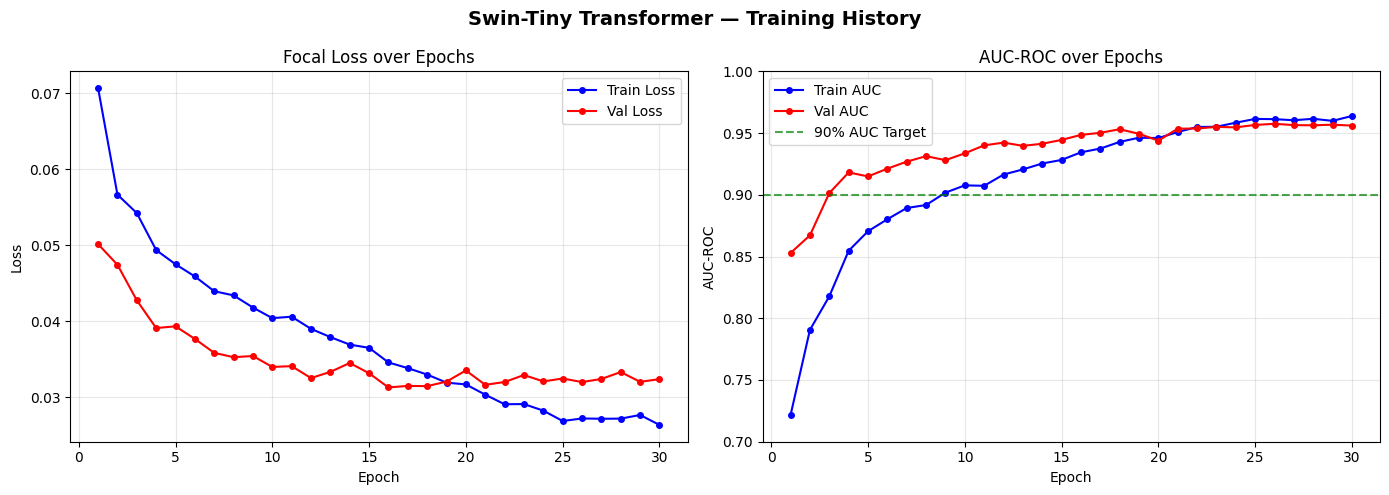

In [12]:

# ── CODE CELL 9: Training Curves ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Swin-Tiny Transformer — Training History', fontsize=14, fontweight='bold')
epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Focal Loss over Epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_auc'], 'b-o', label='Train AUC', markersize=4)
axes[1].plot(epochs_ran, history['val_auc'],   'r-o', label='Val AUC',   markersize=4)
axes[1].axhline(y=0.90, color='green', linestyle='--', alpha=0.7, label='90% AUC Target')
axes[1].set_title('AUC-ROC over Epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC-ROC')
axes[1].legend(); axes[1].grid(alpha=0.3); axes[1].set_ylim([0.7, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'swintiny_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()


## Test Set Evaluation

In [13]:
# ── CODE CELL 10: Final Evaluation with 3-View TTA (FIXED) ────────────────────
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Best checkpoint loaded (epoch {checkpoint['epoch']}, Val AUC: {checkpoint['val_auc']:.4f})")

model.eval()
tta_transforms = [
    lambda x: x,                                         
    lambda x: torch.flip(x, dims=[3]),                    
    lambda x: torch.flip(x, dims=[2]),                    
]

test_labels, test_probs = [], []
with torch.no_grad():
    for images, meta, labels in tqdm(test_loader, desc='  TTA Evaluating', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True) # ✅ FIXED: Shifted tabular arrays to GPU memory
        labels = labels.to(DEVICE, non_blocking=True)

        batch_probs = torch.zeros(images.size(0), device=DEVICE)
        for tta_fn in tta_transforms:
            augmented = tta_fn(images)
            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed both image augmentations and metadata to multi-modal head
                logits = model(augmented, meta)
            batch_probs += torch.sigmoid(logits)
        batch_probs /= len(tta_transforms)

        test_probs.extend(batch_probs.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_auc   = roc_auc_score(test_labels, test_probs)
test_preds = [1 if p >= 0.5 else 0 for p in test_probs]
test_acc   = sum(1 for p, l in zip(test_preds, test_labels) if p == l) / len(test_labels)

print("\n" + "=" * 60)
print(f"  AUC-ROC  : {test_auc:.4f} | Accuracy : {test_acc:.4f}")
print("=" * 60)
print(f"\n  AUC-ROC  : {test_auc:.4f}")
print(f"  Accuracy : {test_acc:.4f}")
print("\n  Classification Report:")
print(classification_report(test_labels, test_preds,
                             target_names=['Benign (0)', 'Malignant (1)'], digits=4))

Best checkpoint loaded (epoch 26, Val AUC: 0.9575)



  AUC-ROC  : 0.9599 | Accuracy : 0.8919

  AUC-ROC  : 0.9599
  Accuracy : 0.8919

  Classification Report:
               precision    recall  f1-score   support

   Benign (0)     0.8771    0.9637    0.9184      1600
Malignant (1)     0.9253    0.7687    0.8398       934

     accuracy                         0.8919      2534
    macro avg     0.9012    0.8662    0.8791      2534
 weighted avg     0.8949    0.8919    0.8894      2534



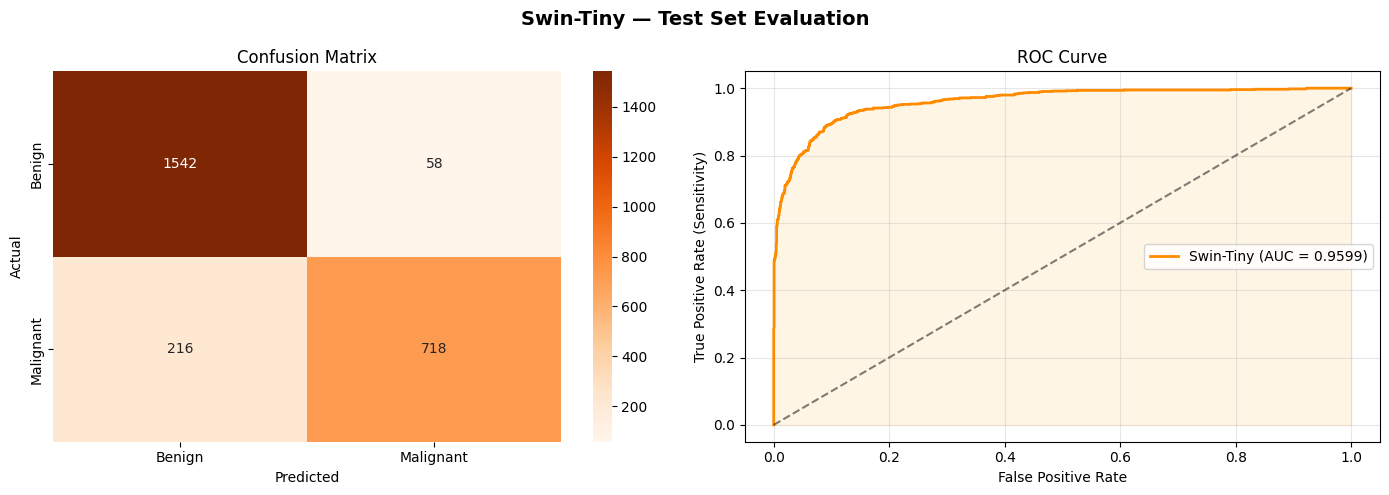

✅ Swin-Tiny predictions saved for ensemble notebook.


In [14]:
# ── CODE CELL 11: Confusion Matrix & ROC ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Swin-Tiny — Test Set Evaluation', fontsize=14, fontweight='bold')

cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr, tpr, 'darkorange', linewidth=2,
             label=f'Swin-Tiny (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='orange')
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'swintiny_evaluation.png'), dpi=150, bbox_inches='tight')
plt.show()

np.save(os.path.join(OUTPUT_DIR, 'swintiny_test_probs.npy'),  np.array(test_probs))
np.save(os.path.join(OUTPUT_DIR, 'swintiny_test_labels.npy'), np.array(test_labels))
print("✅ Swin-Tiny predictions saved for ensemble notebook.")


In [15]:
# ── Val TTA → val_probs for Stacking Ensemble (FIXED) ──────────────────────────
model.eval()
tta_transforms_val = [
    lambda x: x,
    lambda x: torch.flip(x, dims=[3]),
    lambda x: torch.flip(x, dims=[2]),
]
val_all_probs, val_all_labels = [], []

with torch.no_grad():
    for images, meta, labels in tqdm(val_loader, desc='  Val TTA', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True) # ✅ FIXED: Shifted tabular vectors onto GPU memory
        
        batch_probs = torch.zeros(images.size(0), device=DEVICE)
        for tta_fn in tta_transforms_val:
            augmented = tta_fn(images)
            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed validation features and metadata inputs concurrently
                logits = model(augmented, meta)
            batch_probs += torch.sigmoid(logits)
        batch_probs /= len(tta_transforms_val)
        val_all_probs.extend(batch_probs.cpu().numpy())
        val_all_labels.extend(labels.numpy())

val_probs_arr  = np.array(val_all_probs)
val_labels_arr = np.array(val_all_labels).astype(int)
np.save(os.path.join(OUTPUT_DIR, 'swintiny_val_probs.npy'),  val_probs_arr)
np.save(os.path.join(OUTPUT_DIR, 'swintiny_val_labels.npy'), val_labels_arr)
print(f"✅ Swin-Tiny OOF validation arrays saved successfully ({len(val_probs_arr)} records).")
print('All outputs saved for Stacking Ensemble:')
print(f'   swintiny_test_probs.npy   — {len(test_probs)} predictions')
print(f'   swintiny_val_probs.npy    — {len(val_probs_arr)} predictions (for meta-learner)')
print(f'   swintiny_best.pth         — best model weights')


✅ Swin-Tiny OOF validation arrays saved successfully (2533 records).
All outputs saved for Stacking Ensemble:
   swintiny_test_probs.npy   — 2534 predictions
   swintiny_val_probs.npy    — 2533 predictions (for meta-learner)
   swintiny_best.pth         — best model weights
